Restaurant Rating Prediction Machine Learning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Membuat grafik lebih nyaman dibaca
sns.set_theme(style="whitegrid")

print("Semua library berhasil di-import.")

Semua library berhasil di-import.


In [4]:
file_path = "/content/Zomato Restaurant Dataset.csv"
df = pd.read_csv(file_path)

print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head())

Ukuran dataset (baris, kolom): (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [5]:
df.info()

display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


In [7]:
print("Nilai kosong per kolom:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Jumlah Kosong"))

print("Jumlah baris duplikat:", df.duplicated().sum())

Nilai kosong per kolom:


,Jumlah Kosong
Cuisines,9
Restaurant Name,0
Country Code,0
City,0
Restaurant ID,0
Address,0
Locality,0
Longitude,0
Locality Verbose,0
Latitude,0


Jumlah baris duplikat: 0


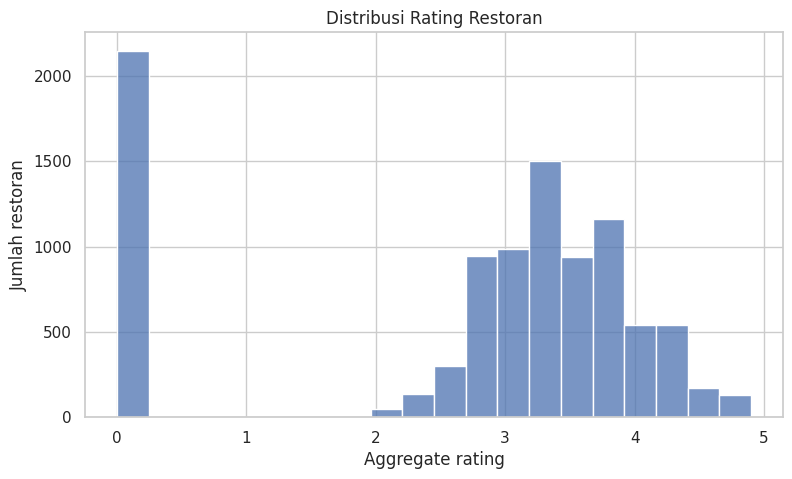

Jumlah rating 0: 2148
Jumlah rating di atas 0: 7403


In [8]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="Aggregate rating", bins=20)
plt.title("Distribusi Rating Restoran")
plt.xlabel("Aggregate rating")
plt.ylabel("Jumlah restoran")
plt.show()

print("Jumlah rating 0:", (df["Aggregate rating"] == 0).sum())
print("Jumlah rating di atas 0:", (df["Aggregate rating"] > 0).sum())

,rata_rata_rating
Price range,
1,3.238885
2,3.377167
3,3.777276
4,3.890957


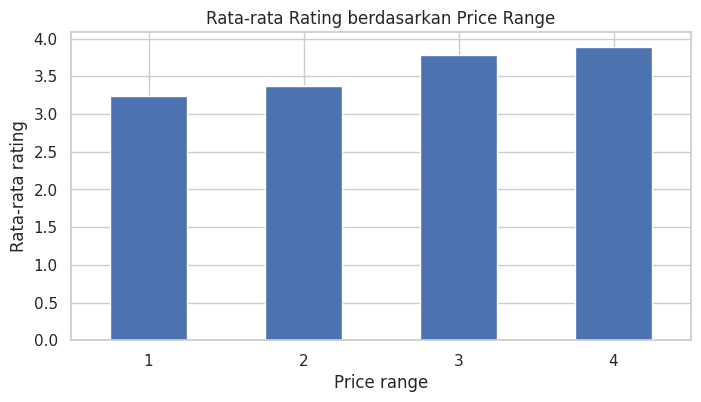

In [9]:
rating_by_price = (
    df[df["Aggregate rating"] > 0]
    .groupby("Price range")["Aggregate rating"]
    .mean()
)

display(rating_by_price.to_frame("rata_rata_rating"))

rating_by_price.plot(kind="bar", figsize=(8, 4))
plt.title("Rata-rata Rating berdasarkan Price Range")
plt.xlabel("Price range")
plt.ylabel("Rata-rata rating")
plt.xticks(rotation=0)
plt.show()

In [10]:
# Gunakan hanya restoran yang memiliki rating
data = df.loc[df["Aggregate rating"] > 0].copy()

numeric_features = [
    "Price range",
    "Votes",
    "Longitude",
    "Latitude",
]

categorical_features = [
    "City",
    "Cuisines",
    "Has Table booking",
    "Has Online delivery",
    "Is delivering now",
]

features = numeric_features + categorical_features
target = "Aggregate rating"

X = data[features]
y = data[target]

print("Jumlah baris yang digunakan:", len(data))
print("Jumlah fitur:", len(features))
print("Fitur:", features)
print("Target:", target)

Jumlah baris yang digunakan: 7403
Jumlah fitur: 9
Fitur: ['Price range', 'Votes', 'Longitude', 'Latitude', 'City', 'Cuisines', 'Has Table booking', 'Has Online delivery', 'Is delivering now']
Target: Aggregate rating


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 5922
Jumlah data testing: 1481


In [12]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing siap.")

Preprocessing siap.


In [13]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="mean"))
])

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

print("Baseline dan Random Forest siap.")

Baseline dan Random Forest siap.


In [14]:
baseline_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Training selesai.")

Training selesai.


In [15]:
def evaluate_model(name, model, X_test, y_test):
    # Membuat prediksi untuk data testing
    predictions = model.predict(X_test)

    # Menghitung metrik evaluasi
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

results = pd.DataFrame([
    evaluate_model("Baseline (mean)", baseline_model, X_test, y_test),
    evaluate_model("Random Forest", random_forest_model, X_test, y_test)
])

display(results.round(3))

,Model,MAE,RMSE,R2
0,Baseline (mean),0.455,0.556,-0.000
1,Random Forest,0.242,0.331,0.647


,Rating sebenarnya,Rating prediksi
0,2.9,2.91
1,3.9,3.28
2,2.8,2.71
3,2.3,3.00
4,3.2,3.12
5,3.0,3.25
6,3.8,3.80
7,3.3,3.61
8,2.5,2.88
9,3.4,3.40


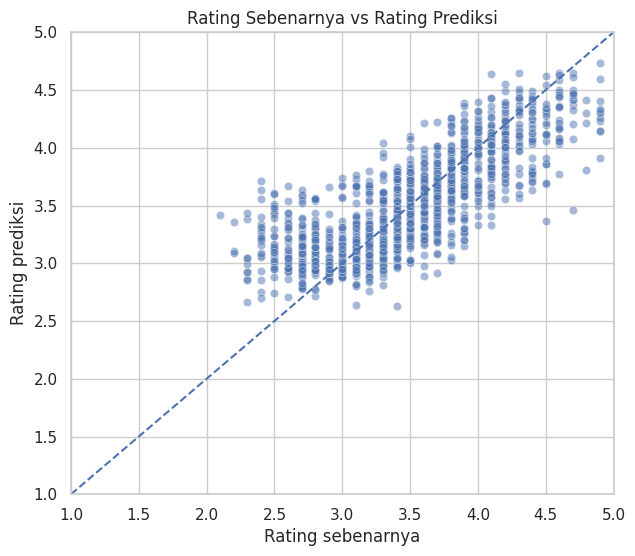

In [16]:
predictions = random_forest_model.predict(X_test)

comparison = pd.DataFrame({
    "Rating sebenarnya": y_test.to_numpy(),
    "Rating prediksi": predictions
})

display(comparison.head(10).round(2))

plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=comparison,
    x="Rating sebenarnya",
    y="Rating prediksi",
    alpha=0.5
)

plt.plot([1, 5], [1, 5], linestyle="--")
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.title("Rating Sebenarnya vs Rating Prediksi")
plt.show()

In [17]:
contoh_restoran = pd.DataFrame([{
    "Price range": 2,
    "Votes": 150,
    "Longitude": 77.60,
    "Latitude": 12.97,
    "City": "Bangalore",
    "Cuisines": "North Indian, Chinese",
    "Has Table booking": "No",
    "Has Online delivery": "Yes",
    "Is delivering now": "No",
}])

prediksi_rating = random_forest_model.predict(contoh_restoran)[0]

print(f"Perkiraan rating restoran: {prediksi_rating:.2f} / 5")

Perkiraan rating restoran: 3.97 / 5
